# CM laser: cluster position, stability, static sector pattern and per-module space charge (2026-10-23)

**Data.** The merged aggregated pads of every block (per pad: ADC and hits summed over all laser flashes), dumped on SDCC with
`Fun4All_DumpLaserPads.C`: 14 beam blocks of 79508 / 79513 / 79516 (one fill, 1.8–2.7 µA), 80892 (5.4–5.9 µA), 81558
(6.1–6.7 µA), and the no-beam runs 78242 (field off), 75073 and 83319 (field on). `cmpads.cluster` is a line-by-line copy of
`LaserAggregatedClusterizer` and reproduces the module's clusters exactly (Section 1). Every cluster is matched to the
final-configuration matcher QA (f9_sper with beam, f9_s795 without) for its truth stripe and its PHGarfield correction, so all
position estimators are compared on the same clusters with the same correction.

**What "residual" means here**: cluster φ (estimator) + PHGarfield correction of that cluster (final configuration) − truth φ.
**Truth**: the raw CM truth table, *no* field-off truth alignment applied. Run-to-run differences do not depend on it (same truth
in both blocks); the alignment is a rotation (constant dφ → ring means) and dx, dy (→ the translation term), so the sector
patterns of Sections 6–8 do not depend on it either. The DNL / S-curve does not use truth at all.

**Position estimators** (φ, relative to the max-ADC pad; pad φ decreases with pad index):
* **module centroid** – what the code does: ADC-weighted pad centres of the cluster's own pads (both rows);
* **3-pad COG (seed row / 2 rows)** – the 3 pads around the max pad from the raw pad sums (no hits-per-flash cut), one row or
  summed over the cluster's two rows (the pad grids of the rows of one module are aligned);
* **Gaussian fit** – pad-integrated Gaussian on ±4 pads (unstable: the stripe image is narrower than a pad);
* **DNL-corrected** – the position mapped through the measured S-curve of its block, side and ring (u → CDF(u) − ½).

**Results**
1. Pad response: stripe image σ ≈ 0.3–0.5 pad; ~18 % of clusters have one pad in their main row. Module-centroid S-curve
   150–400 µm peak-to-peak (more at high current), 3-pad COG 50–100 µm. Field off: wider image and a larger S-curve, as expected.
2. Single-stripe errors of ~100–250 µm remain with every estimator, also after the DNL correction (the S-curve is only the average
   part): they are fixed while the stripe sits on the same pads and renewed when the distortion moves it by ≳ 0.3 pad, so the
   stripe "jitter" between blocks grows with |ΔI| and saturates. They average out over a module.
3. **Static**: one sector static for all 14 beam blocks + a per-module slope vs I + per-fill ring means and translation fits all
   blocks to 0.09 mrad; the static sector pattern extrapolated to I = 0 is the one of the no-beam field-on runs (correlation
   0.83–0.91 on both sides). It is a per-module static of 0.5–0.75 mrad rms that our static model does not contain.
4. **Gain**: the per-module slope (0.22 mrad/µA rms) is described by the 72 v12 module maps with module charges redistributed by
   ±12–17 % rms at fixed charge per ring (residual slope 0.12–0.14 mrad/µA); the weights are stable when a fill is left out
   (correlation ≥ 0.99). Maps and configs for all 14 beam blocks are built (v13: gain, gain/2, unconstrained; condor).

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display
import cmpos as cm
plt.rcParams['figure.dpi'] = 72
T = cm.tables()
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')

## 1. Re-clustering from the pad dumps reproduces the module
Per block: number of dumped pads and laser flashes, clusters from the python copy and from the module (QA tree), whether the
sorted ADC sums are identical and the largest difference of the sorted cluster radii.

In [2]:
cm.validation_table()

block                                     pads flashes python clusters module clusters  ADC sums identical  max |dR| [um]
79513/1000                              137913    8594            5687            5687  True                0.03
81558/0                                 142341    8281            6193            6193  True                0.03
75073/0 (no beam, field on)              51524    4219            5459            5459  True                0.03
78242/0 (no beam, field off)            109380  205167            6458            6458  True                0.03


## 2. Pad response of a CM stripe
### 2a. Seed-row pad profiles
**Plotted**: for 12 example clusters (R1/R2/R3 × 1–4 pads in the main row), the ADC per flash of the 9 pads around the max pad
in the cluster's main ("seed") row. Orange = pads the module kept, grey = pads present in the pad sums but dropped by the
hits-per-flash cut or the flood fill. Vertical lines: position of each estimator in pad units. Single-pad rows (first column):
the module centroid sits exactly on the pad centre although the neighbour pads carry signal.

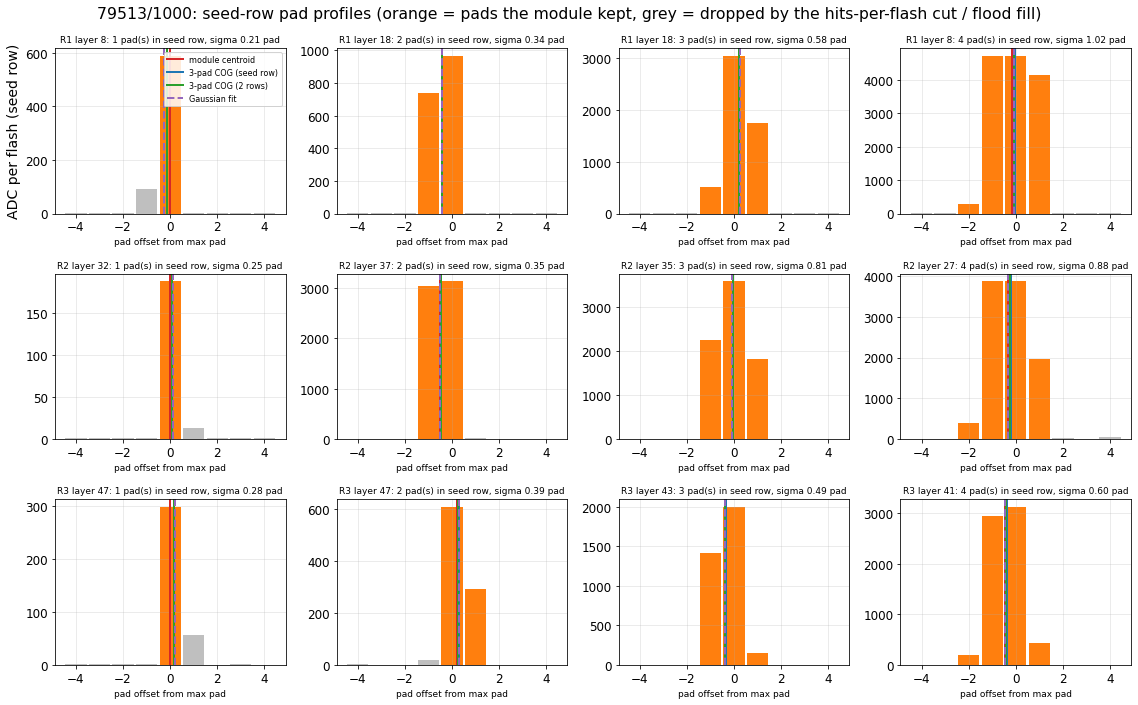

In [3]:
show(cm.fig_pad_profiles(('79513', 1000)))

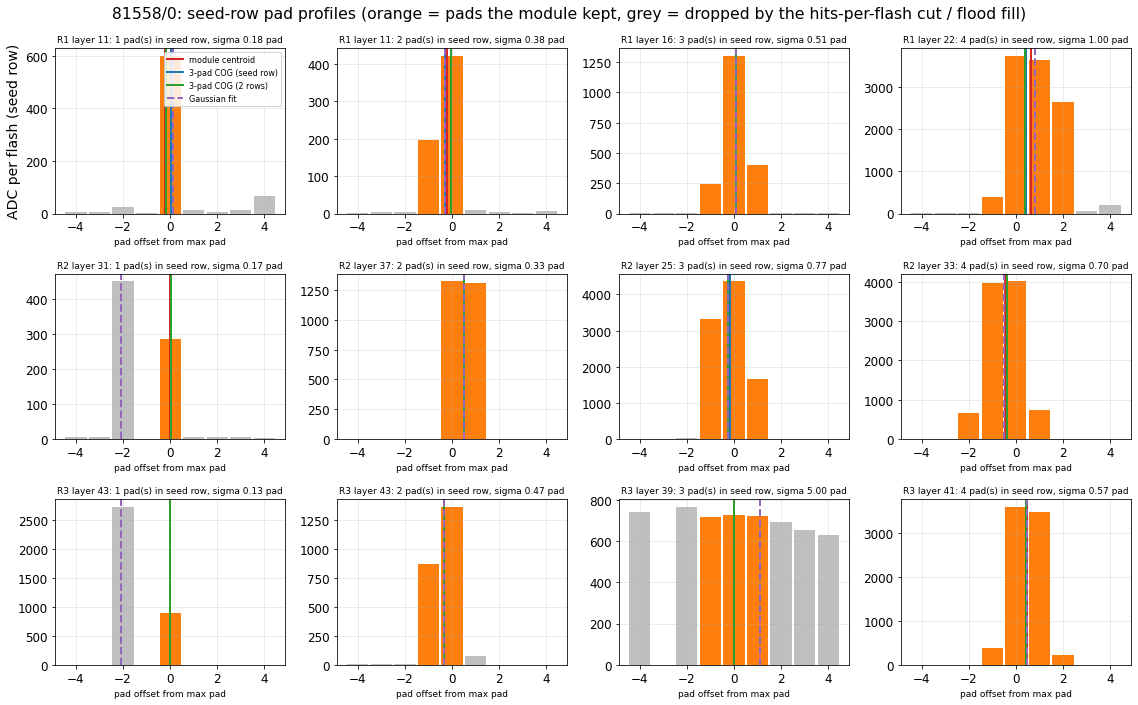

In [4]:
show(cm.fig_pad_profiles(('81558', 0), seed=5))

### 2b. Pads per cluster in the seed row
**Plotted**: fraction of clusters with 1, 2, 3 … pads in the seed row, per ring, for two beam blocks, field-on and field-off
no-beam runs.

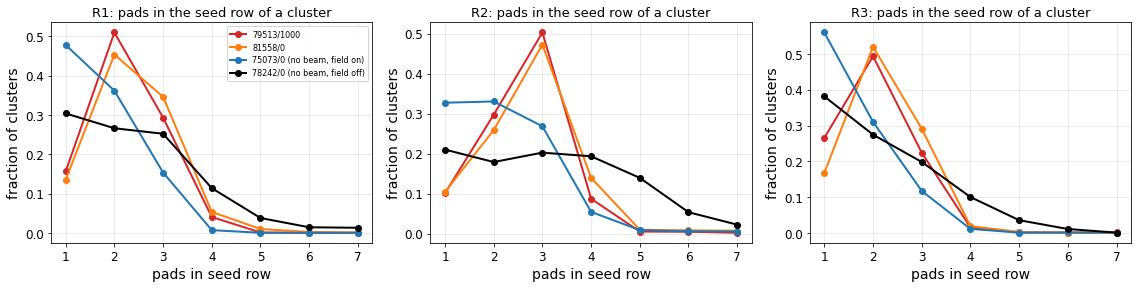

In [5]:
show(cm.fig_multiplicity())

### 2c. Width of the stripe image
**Plotted**: median σ of a pad-integrated Gaussian fitted to the seed-row profile (converted to µm at the stripe radius), per
block (grey band: no beam). Field off (78242) is wide (no ωτ suppression of transverse diffusion); field on without beam is
narrow; with beam the image is wider and grows with the current: the distortion is not constant during a block.

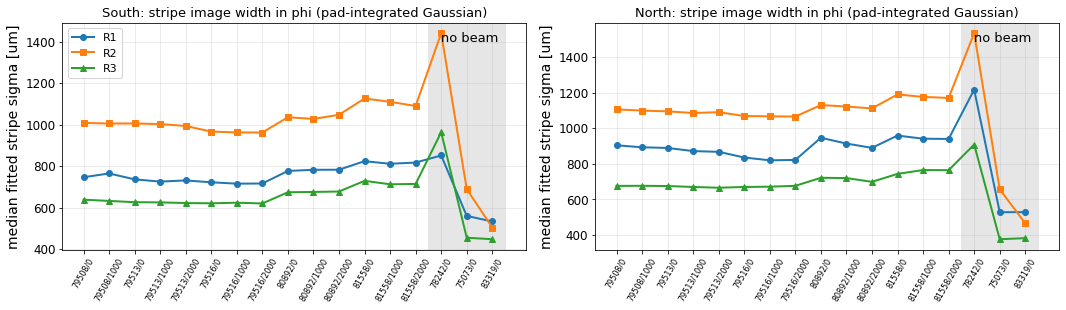

In [6]:
show(cm.fig_sigma())

## 3. DNL and S-curve
### 3a. Position relative to the max pad (differential non-linearity)
**Plotted**: histogram of u = (φ_estimator − φ_max pad) / pad pitch per ring, normalised to its mean in |u| < ½. For an unbiased
estimator and evenly spread stripe positions it is flat. The module centroid piles up at u = 0 (single-pad rows).

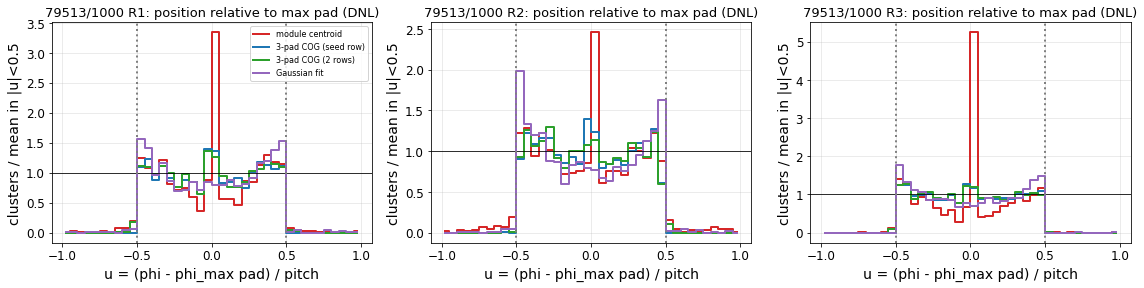

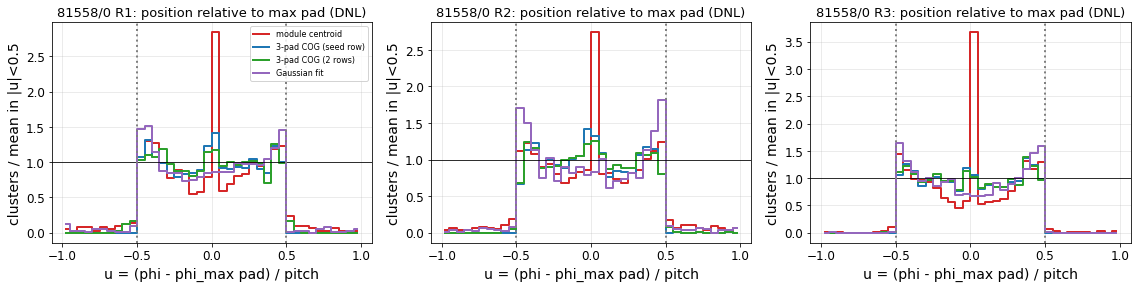

In [7]:
show(cm.fig_dnl(('79513', 1000)), cm.fig_dnl(('81558', 0)))

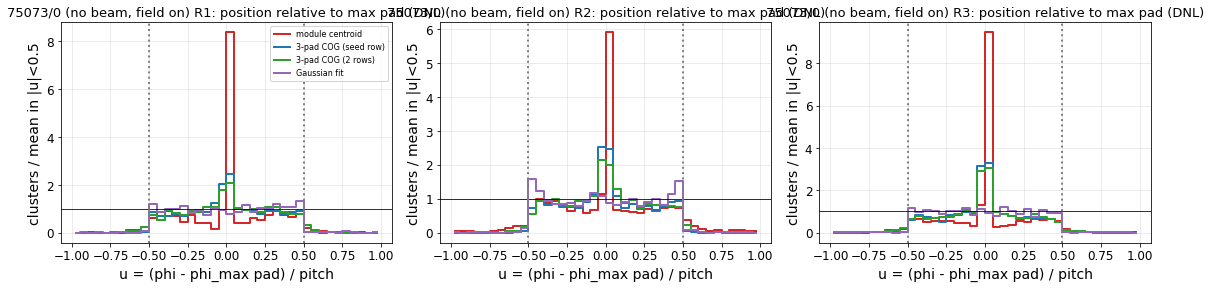

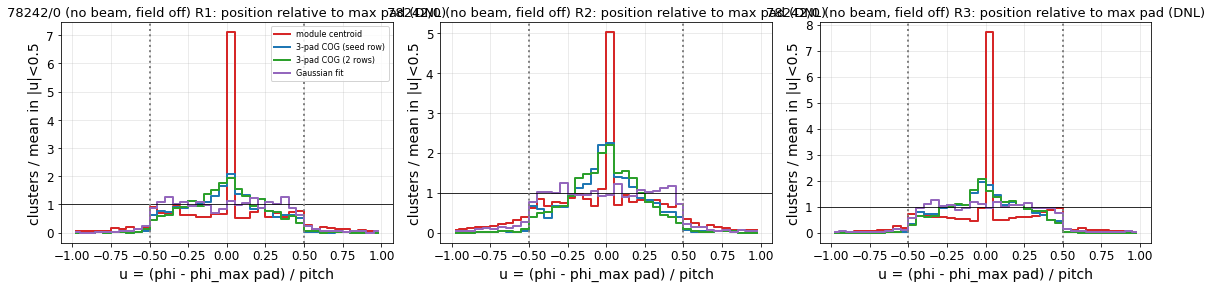

In [8]:
show(cm.fig_dnl(('75073', 0)), cm.fig_dnl(('78242', 0)))

### 3b. S-curves
**Plotted**: bias (estimator − true position, R·Δφ in µm) vs true position inside the pad, obtained by integrating the DNL
(u_true = CDF(u) − ½; median per bin). Top: module centroid, bottom: 3-pad COG (2 rows). Beam (red, orange) moves the stripes
by mm, so the true positions are evenly spread; without beam (blue, black) they stay where the pattern puts them, so the
assumption is weaker – but the larger S-curve with the field off (wider image, larger diffusion) is the expected behaviour.

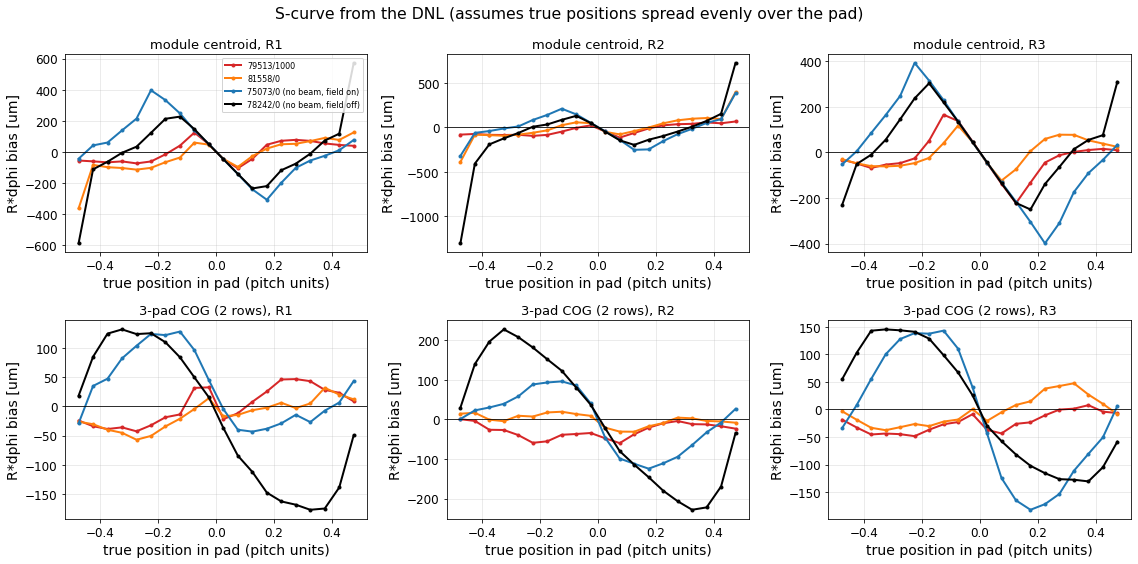

In [9]:
show(cm.fig_scurve())

In [10]:
cm.scurve_table()

S-curve peak-to-peak [um] per ring R1/R2/R3 (median profile)
block                                         module centroid   3-pad COG (seed row)     3-pad COG (2 rows)           Gaussian fit
79508/0                                           208/155/377              125/63/89              127/68/83            583/295/215
79513/1000                                        230/181/388               89/85/57               89/61/56            308/303/200
79516/0                                           226/188/397              105/98/76              110/63/68            289/299/226
80892/0                                           308/830/283               79/68/64               69/56/69          1808/2202/199
81558/0                                           489/785/241               79/78/87               89/51/85          1672/3542/213
75073/0 (no beam, field on)                       705/706/791            244/299/383            171/221/325           167/5343/698
83319/0 (no beam, fiel

### 3c. Intensity dependence of the S-curve
**Plotted**: the S-curve for the three terciles of cluster ADC (blue lowest). The module centroid depends on the intensity
(the hits-per-flash cut moves pads in and out); the 3-pad COG much less.

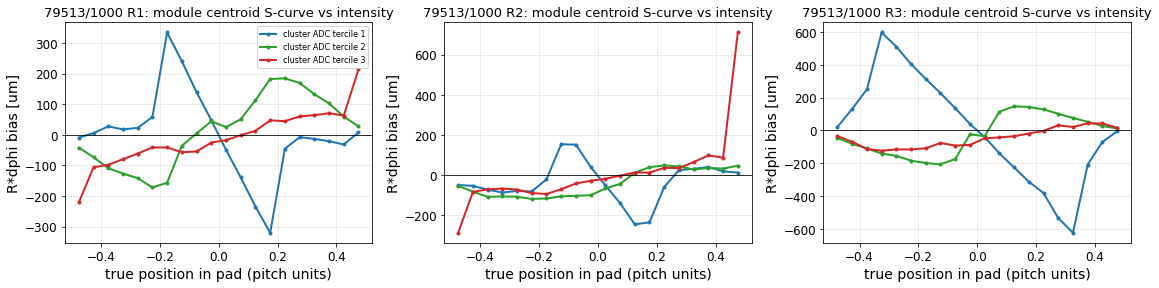

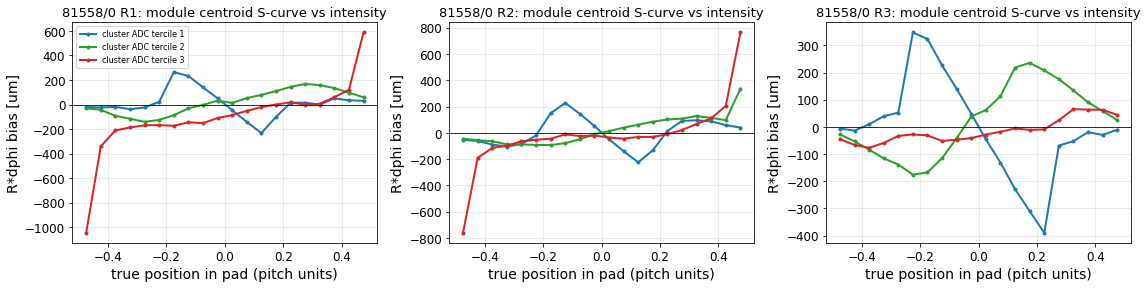

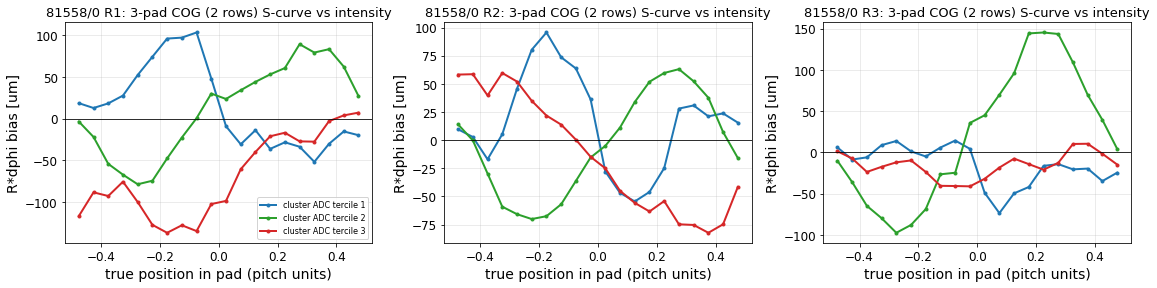

In [11]:
show(cm.fig_scurve_intensity(('79513', 1000), 'mod'), cm.fig_scurve_intensity(('81558', 0), 'mod'), cm.fig_scurve_intensity(('81558', 0), 'cog3r2'))

## 4. Single-stripe resolution, before and after the DNL correction
**Plotted / tabulated**: within one block, each stripe's residual minus the median residual of its 8 nearest stripes in the same
module (removes the smooth distortion), robust rms in µm. This is the single-stripe position error (pad-level errors + small-scale
distortion + statistics). The DNL correction removes only the *average* S-curve: it helps little because most of the error is
stripe-specific (which pads, their gains, the per-sample threshold on the weak neighbour pad).

single-stripe scatter around its 8 neighbours, robust rms [um], S R1/R2/R3 | N R1/R2/R3
79513/1000
   module centroid                       225  198  213 |  234  135  188
   module centroid, DNL-corrected        186  186  273 |  246  146  179
   3-pad COG (2 rows)                    184  174  131 |  225  157  143
   3-pad COG (2 rows), DNL-corrected     163  173  142 |  213  151  127
81558/0
   module centroid                       290  284  234 |  385  196  210
   module centroid, DNL-corrected        291  286  239 |  408  218  192
   3-pad COG (2 rows)                    263  257  165 |  424  220  176
   3-pad COG (2 rows), DNL-corrected     261  255  164 |  427  231  152
75073/0 (no beam, field on)
   module centroid                       526  435  276 |  486  536  665
   module centroid, DNL-corrected        633  437  341 |  580  617  773
   3-pad COG (2 rows)                    453  376  211 |  463  575  636
   3-pad COG (2 rows), DNL-corrected     448  388  244 |  485  603  658
7

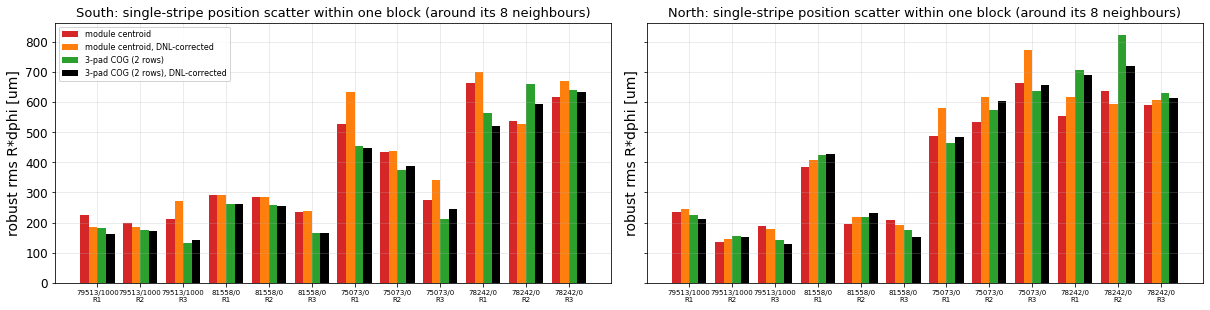

In [12]:
show(cm.fig_resolution())

## 5. Stripe stability between blocks
**Plotted**: per stripe, run change of the residual between two blocks minus the median change of its 8 nearest stripes (only
the stripe-to-stripe part is left), robust rms in mrad, for block pairs inside one run, inside one fill, between fills, and the
two no-beam runs.

stripe-to-stripe run change, robust rms [mrad], S R1/R2/R3 | N R1/R2/R3
79513/0 - 79513/1000 (same run)
   module centroid        0.024 0.021 0.024 | 0.034 0.018 0.017
   3-pad COG (seed row)   0.030 0.021 0.021 | 0.033 0.019 0.021
   3-pad COG (2 rows)     0.029 0.020 0.020 | 0.032 0.019 0.020
   Gaussian fit           0.040 0.028 0.032 | 0.045 0.026 0.033
79513/1000 - 79513/2000 (same run)
   module centroid        0.021 0.020 0.021 | 0.043 0.023 0.017
   3-pad COG (seed row)   0.028 0.019 0.022 | 0.043 0.024 0.021
   3-pad COG (2 rows)     0.027 0.019 0.020 | 0.039 0.023 0.020
   Gaussian fit           0.039 0.025 0.031 | 0.048 0.027 0.031
79508/0 - 79513/0 (same fill)
   module centroid        0.399 0.241 0.382 | 0.418 0.189 0.344
   3-pad COG (seed row)   0.290 0.211 0.221 | 0.338 0.218 0.211
   3-pad COG (2 rows)     0.288 0.213 0.203 | 0.327 0.212 0.207
   Gaussian fit           0.394 0.317 0.309 | 0.453 0.362 0.364
79513/0 - 79516/0 (same fill)
   module centroid        0.218 0

   3-pad COG (seed row)   0.182 0.114 0.138 | 0.207 0.100 0.144
   3-pad COG (2 rows)     0.180 0.112 0.127 | 0.204 0.099 0.142
   Gaussian fit           0.242 0.167 0.214 | 0.270 0.162 0.228
79508/1000 - 79516/1000 (same fill)
   module centroid        0.470 0.299 0.460 | 0.497 0.244 0.341
   3-pad COG (seed row)   0.369 0.279 0.229 | 0.461 0.270 0.226
   3-pad COG (2 rows)     0.360 0.278 0.222 | 0.448 0.259 0.219
   Gaussian fit           0.523 0.421 0.320 | 0.559 0.443 0.386
80892/0 - 80892/2000 (same run)
   module centroid        0.422 0.161 0.341 | 0.368 0.125 0.305
   3-pad COG (seed row)   0.321 0.145 0.214 | 0.304 0.158 0.209
   3-pad COG (2 rows)     0.296 0.144 0.203 | 0.284 0.151 0.208
   Gaussian fit           0.461 0.215 0.299 | 0.421 0.249 0.345
81558/0 - 81558/2000 (same run)
   module centroid        0.402 0.172 0.382 | 0.415 0.145 0.311
   3-pad COG (seed row)   0.286 0.154 0.226 | 0.343 0.163 0.213
   3-pad COG (2 rows)     0.295 0.163 0.217 | 0.338 0.152 0.210


   Gaussian fit           0.419 0.244 0.324 | 0.537 0.313 0.353
80892/0 - 81558/0 (other fill)
   module centroid        0.733 0.359 0.409 | 0.650 0.235 0.325
   3-pad COG (seed row)   0.511 0.304 0.227 | 0.585 0.273 0.227
   3-pad COG (2 rows)     0.482 0.310 0.216 | 0.585 0.276 0.224
   Gaussian fit           0.745 0.418 0.326 | 0.760 0.457 0.365
79513/0 - 80892/0 (other fill)
   module centroid        0.908 0.526 0.475 | 1.006 0.443 0.446
   3-pad COG (seed row)   0.841 0.522 0.303 | 1.160 0.529 0.324
   3-pad COG (2 rows)     0.817 0.494 0.285 | 1.049 0.501 0.323
   Gaussian fit           0.978 0.642 0.422 | 1.187 0.618 0.429
79513/0 - 81558/0 (other fill)
   module centroid        0.869 0.561 0.411 | 1.062 0.452 0.308
   3-pad COG (seed row)   0.777 0.542 0.268 | 1.208 0.531 0.249
   3-pad COG (2 rows)     0.761 0.522 0.259 | 1.114 0.524 0.250
   Gaussian fit           0.915 0.661 0.317 | 1.257 0.699 0.272
75073/0 - 83319/0 (no beam, months apart)
   module centroid        2.572 1

   3-pad COG (2 rows)     1.955 1.073 0.261 | 1.589 1.405 1.464
   Gaussian fit           1.605 1.259 0.436 | 1.755 1.292 1.277


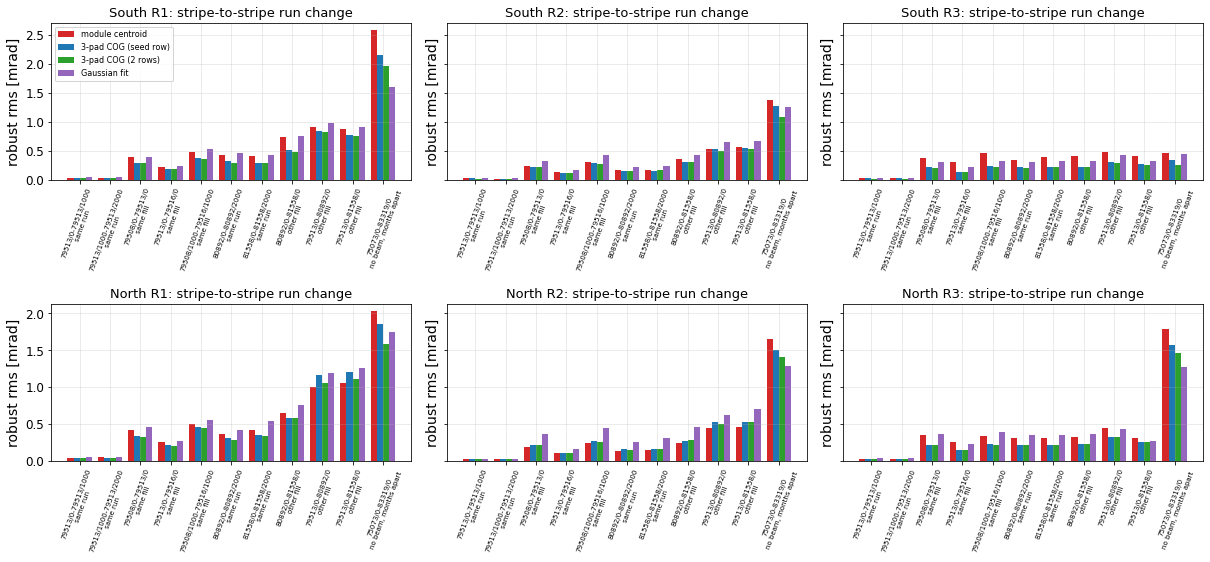

In [13]:
show(cm.fig_jitter())

### 5a. The stripe jitter follows |ΔI| …
**Plotted**: the same quantity for every pair of blocks inside a fill vs the current difference (filled South, open North).
Blocks with the same current agree to 0.01–0.06 mrad whatever the time between them.

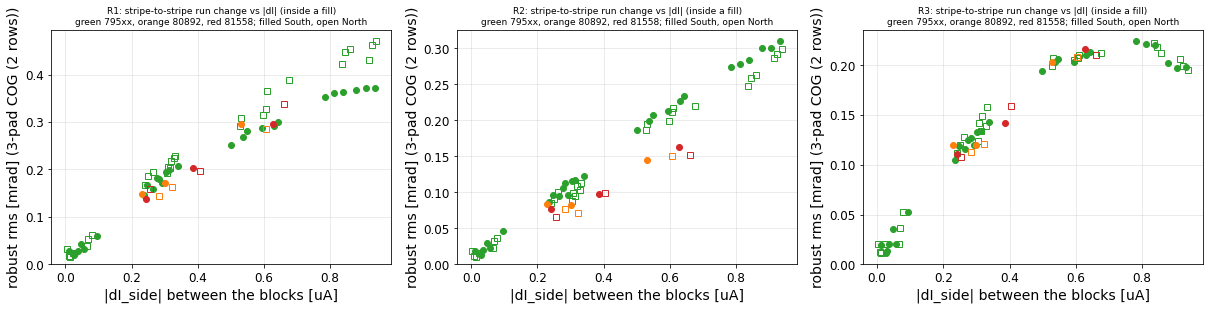

In [14]:
show(cm.fig_jitter_vs_dI())

Mean over block pairs in |ΔI| bins, for the four estimators (module centroid and 3-pad COG, each with and without DNL correction):

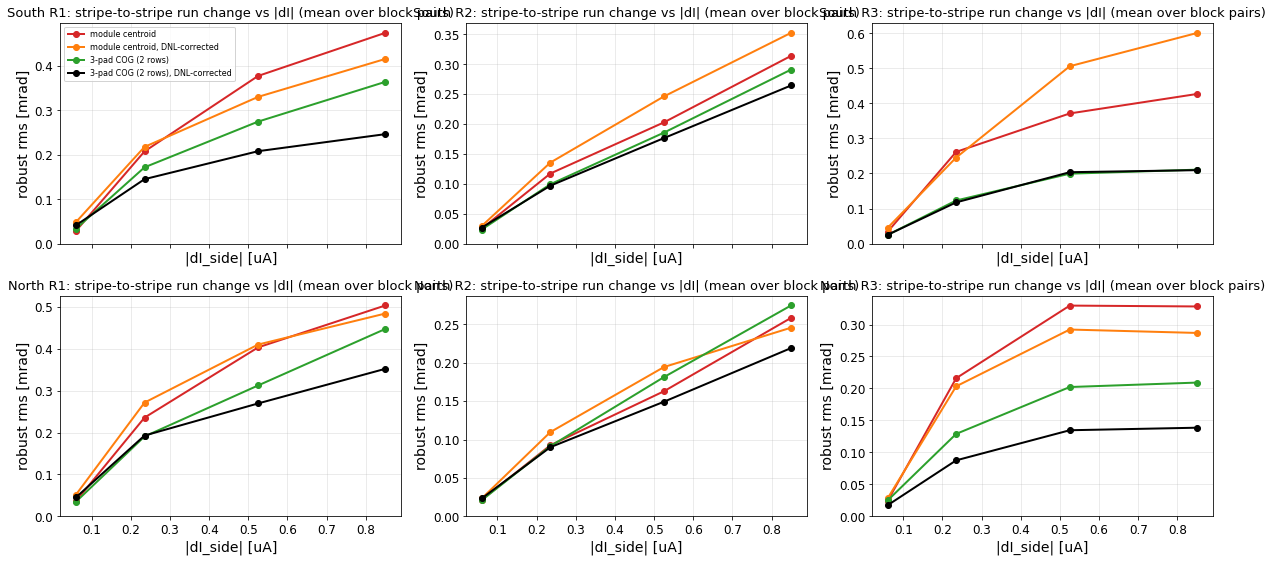

In [15]:
show(cm.fig_jitter_vs_dI_all())

### 5b. … because the stripe moves on the pad plane
**Plotted**: the stripe-to-stripe change binned in how far the stripe moved on the pad plane between the two blocks (in pads).
It rises up to ≈ 0.3–0.5 pad and then levels off: a fixed per-stripe error tied to the pads under the stripe, renewed once the
stripe moves – not small-scale space charge, which would keep growing with ΔI.

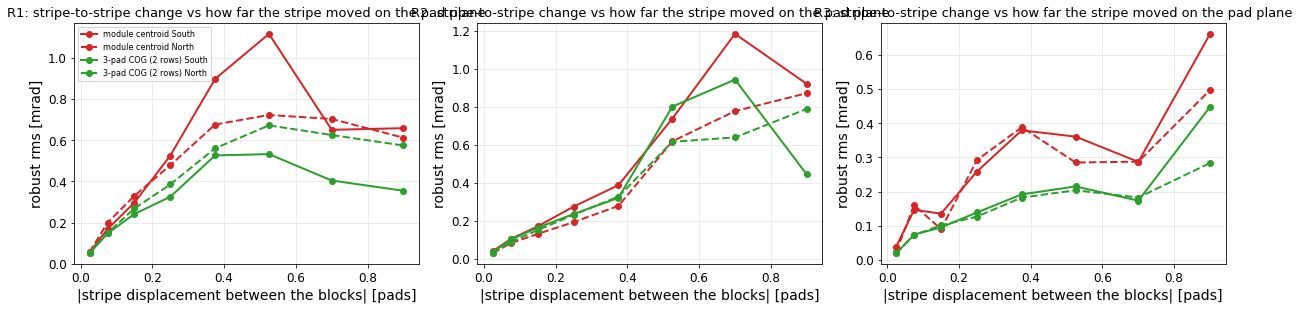

In [16]:
show(cm.fig_jitter_vs_shift())

### 5c. Stripe change vs stripe brightness change (only North R1 shows a correlation)

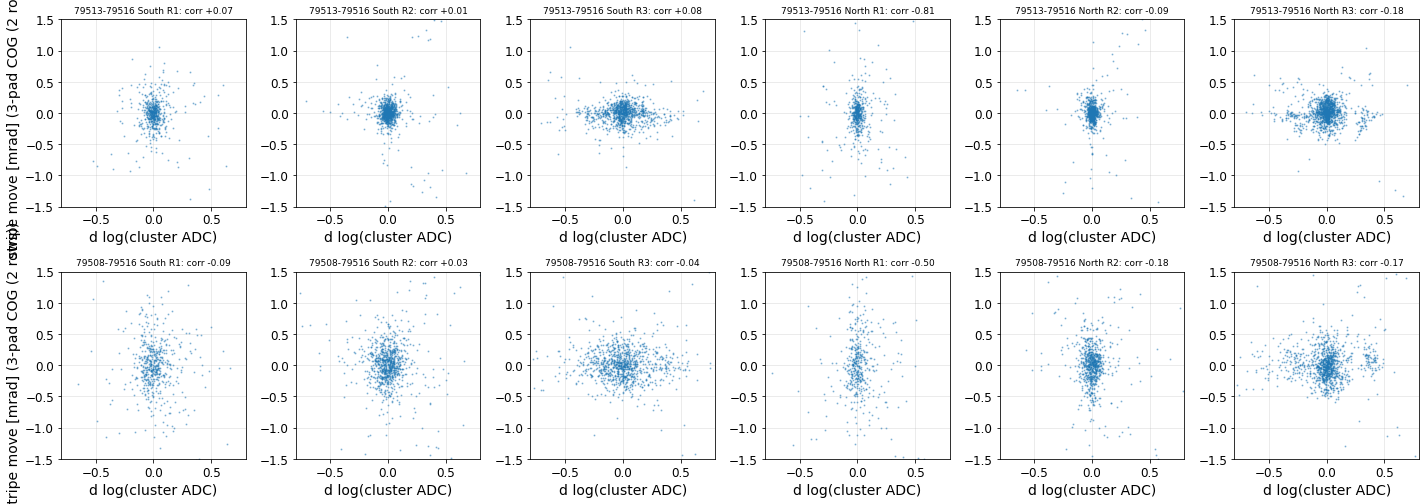

In [17]:
show(cm.fig_moves_vs_adc())

## 6. Module level: what changes between blocks
### 6a. The estimator does not matter for module medians
rms difference of the module-median run change (module centroid vs 3-pad 2-row) per ring, with the statistical error of a module
median in brackets.

In [18]:
cm.estimator_module_compare()

module-level change: module centroid vs 3-pad 2-row, per side R1/R2/R3: rms difference [mrad] (stat error)
79508-79516  same fill (I 2.7 -> 1.9 uA)      South: 0.076(0.066) 0.045(0.054) 0.047(0.025) North: 0.104(0.089) 0.044(0.053) 0.016(0.027)
79513-80892  other fill (I 2.1 -> 5.9 uA)     South: 0.098(0.250) 0.083(0.099) 0.086(0.053) North: 0.153(0.223) 0.116(0.092) 0.073(0.053)
79513-81558  other fill (I 2.1 -> 6.7 uA)     South: 0.130(0.253) 0.112(0.117) 0.106(0.056) North: 0.273(0.282) 0.126(0.110) 0.040(0.051)
80892-81558  other fill (I 5.9 -> 6.7 uA)     South: 0.080(0.083) 0.089(0.053) 0.051(0.029) North: 0.144(0.092) 0.042(0.039) 0.041(0.030)
75073-83319  no beam, field on                South: 0.260(0.482) 0.148(0.196) 0.128(0.062) North: 0.289(0.417) 0.144(0.224) 0.117(0.235)


### 6b. Decomposition per pair
Run change of the module medians (12 sectors × 3 rings) = ring means c (φ-symmetric: space-charge level, field cage, frames) +
translation (dx, dy) of the pattern + sector-to-sector rest. The rest is far above its statistical error even inside a fill.

In [19]:
M = cm.module_table()

module-level run change (3-pad COG (2 rows)), per side: ring means c [mrad], pattern translation dx dy [um],
rms of the sector-to-sector rest [mrad] vs its statistical error, chi2/ndf of the translation-only model
79508/0 - 79516/0: same fill (I 2.7 -> 1.9 uA)
   South: c R1/R2/R3 +0.02 -0.03 -0.07 | dx   -17 dy    -9 um | rest rms 0.185 (stat 0.049) | chi2/ndf 18.1
   North: c R1/R2/R3 -0.01 -0.08 +0.02 | dx    +2 dy   +33 um | rest rms 0.213 (stat 0.049) | chi2/ndf 10.2
79513/0 - 80892/0: other fill (I 2.1 -> 5.9 uA)
   South: c R1/R2/R3 +0.41 -0.28 +0.06 | dx    -5 dy   +97 um | rest rms 0.632 (stat 0.099) | chi2/ndf 45.1
   North: c R1/R2/R3 -0.84 -1.12 -0.86 | dx  -109 dy   -80 um | rest rms 0.686 (stat 0.093) | chi2/ndf 21.7
79513/0 - 81558/0: other fill (I 2.1 -> 6.7 uA)
   South: c R1/R2/R3 +0.64 +0.14 +0.70 | dx   -23 dy  +118 um | rest rms 0.804 (stat 0.113) | chi2/ndf 57.9
   North: c R1/R2/R3 +0.26 -0.21 +0.01 | dx  -119 dy   -97 um | rest rms 0.725 (stat 0.110) | chi2/ndf 

**Plotted** (maps): left of each pair the module change minus its mean, right the rest after ring means and translation; colour in mrad.

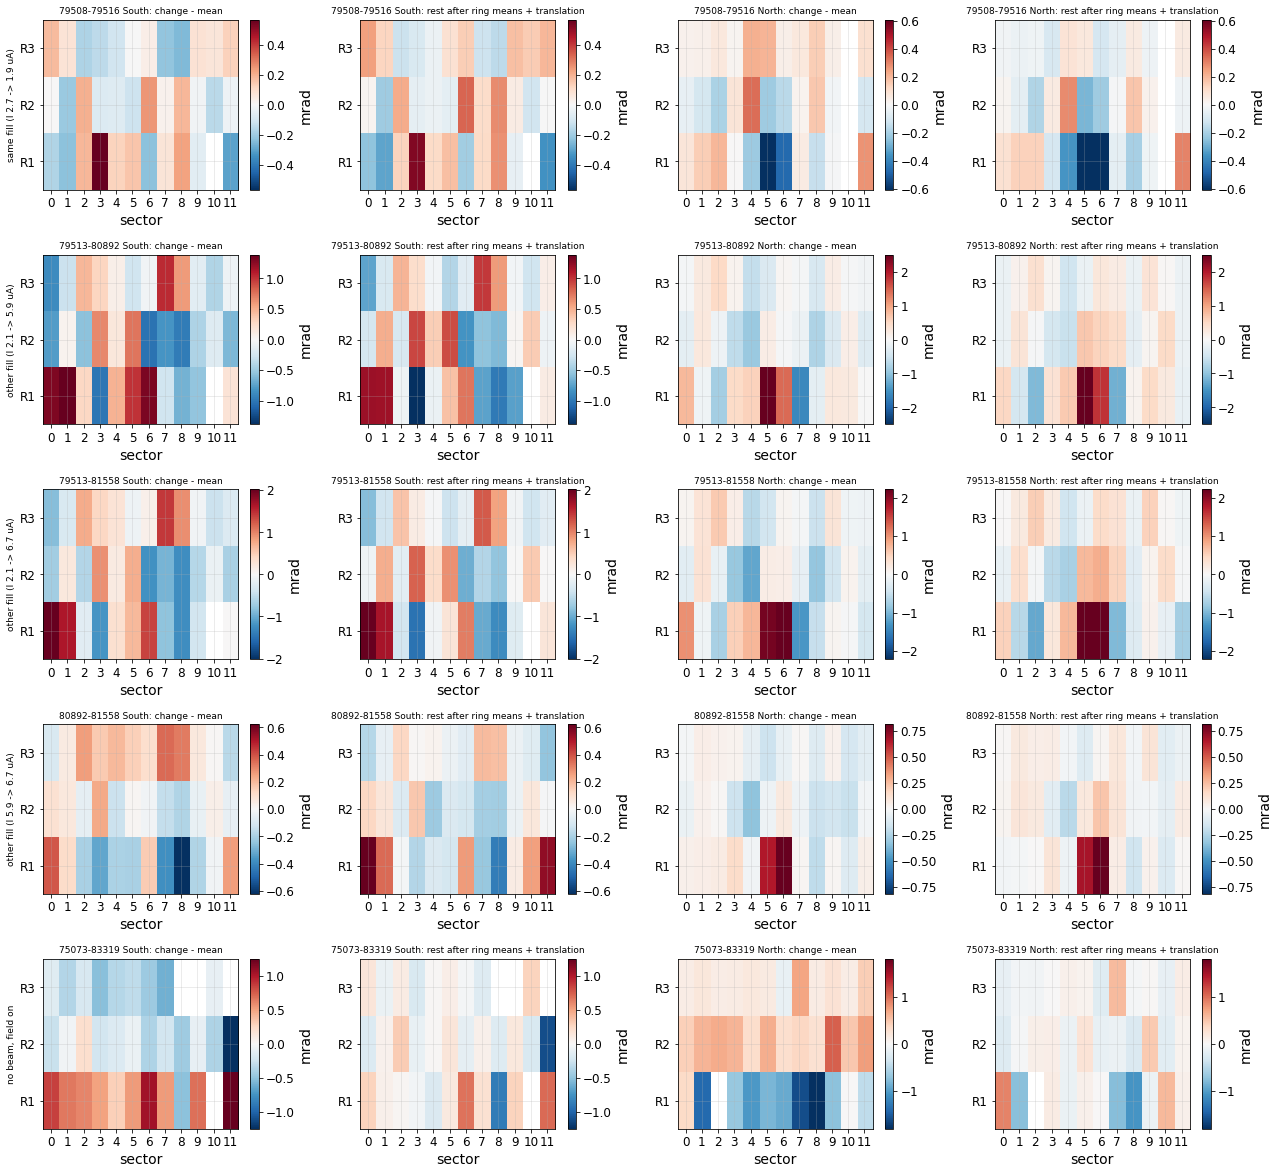

In [20]:
show(cm.fig_module_maps())

**Plotted** (profiles), step by step:
1. per stripe and block: **dφ = cluster φ (3-pad COG, 2 rows) + PHGarfield correction of the final configuration − truth φ** [mrad]
   (the residual left after our full correction);
2. for a **pair of blocks A − B** (legend: e.g. 79508/0 − 79516/0, currents 2.7 → 1.9 µA): per stripe, dφ_A − dφ_B, using only
   stripes seen in both blocks (same truth stripe, so truth and alignment cancel);
3. per pad module (one sector × one ring): the **median** of dφ_A − dφ_B over its stripes (~100 stripes);
4. the **mean over the 12 sectors of the ring is subtracted** (the φ-symmetric part, shown separately in 6c), leaving how
   each sector changed relative to the others.

x = φ of the module centre, one panel per side and ring; each curve is one pair of blocks (not a function of run number);
error bar = statistical error of the module median (1.25 × robust σ / √n). Scale ±1 mrad (the cross-fill R1 changes go beyond).
Grey (in-fill) and purple (80892 → 81558, ΔI 0.8 µA) are small; orange / red (79513 → 8xxxx, ΔI ≈ 4 µA) large with the same
shape and opposite sign to grey (ΔI of opposite sign); blue = the two no-beam runs (no space-charge change).

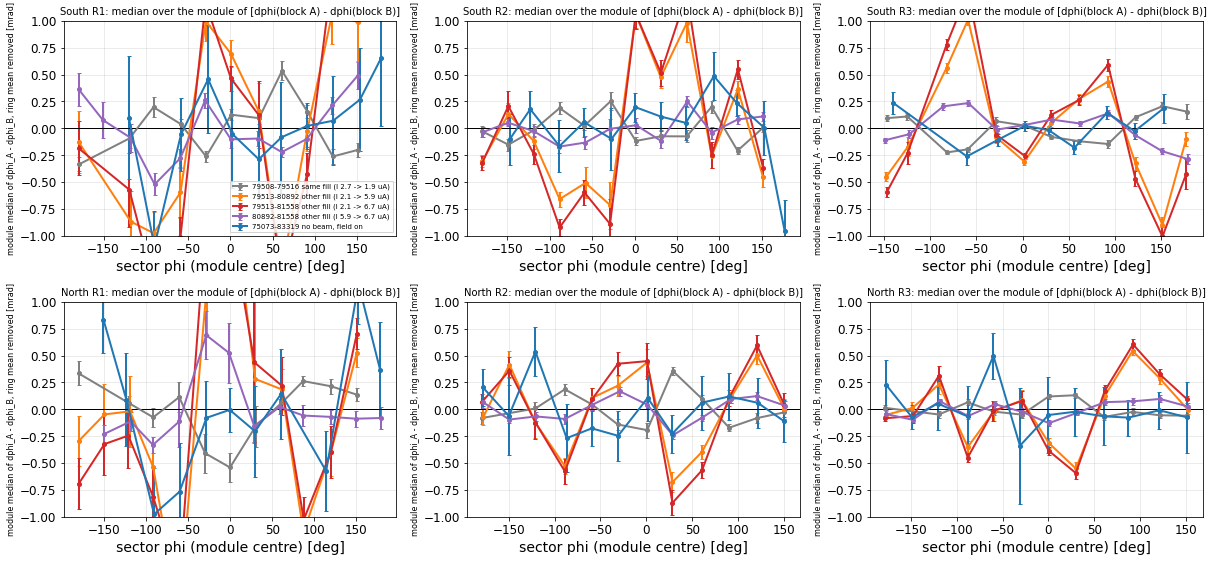

In [21]:
show(cm.fig_module_profiles())

### 6c. Translation and ring means vs current
**Plotted**: for every block, the translation dx, dy of its module pattern and its ring means relative to 79513/0, vs the block's
current (no-beam runs at −0.5). Inside a fill nothing moves; between fills the pattern shifts by ~100–200 µm and the ring means
by up to 1 mrad – period static (field cage / frames), as found before.

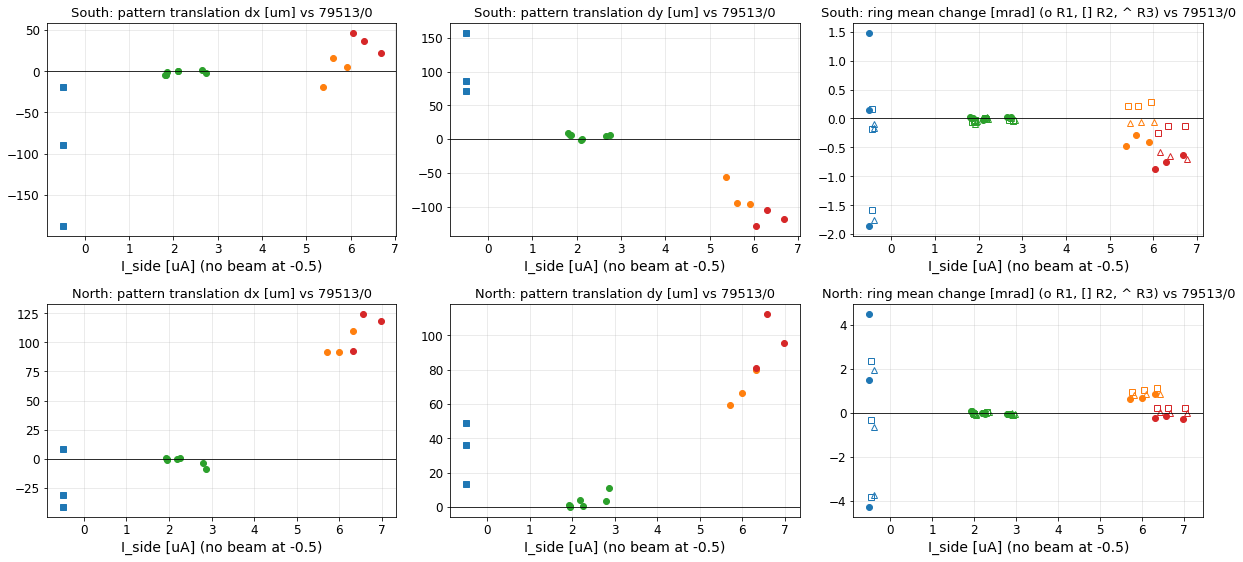

In [22]:
show(cm.fig_translation_vs_current())

### 6d. The removed global terms per block: is it alignment?
Per block and side, from the **absolute** module medians of the residual (vs the raw CM truth, no truth alignment applied):
ring means c (R1, R2, R3), rotation = their mean, R dependence = c_R3 − c_R1, translation dx, dy of the pattern, and the rms of
the sector rest; right part: the same relative to 79513/0. The first line per side is the field-off truth alignment of 78242
(rigid fit of RΔφ, `truthalign.align`).

How to read it: a mechanical offset between the CM and a pad plane is the same with and without beam, in every fill, and the
same rotation in every ring. Field off (78242, no E×B) measures it directly; with the field on the rotation also contains the
E×B φ-shift of the static radial fields, so the field-on rotation is not alignment.

In [23]:
Gt = cm.global_table()

absolute (vs raw CM truth) and relative to 79513/0, per side:
  ring means c R1/R2/R3 [mrad], rotation = their mean, R3-R1, translation dx dy [um], sector rest rms [mrad]
South   (field-off truth alignment 78242: rot -2.03 mrad, dx -605 um, dy +358 um)
  block                                    I |   c R1   c R2   c R3    rot  R3-R1     dx     dy  rest ||  d rot d R3-R1   d dx   d dy
  79508/0                               2.74 |  +0.46  -0.37  -0.33  -0.08  -0.79   -502   +386  0.66 ||  -0.05   +0.03    -14    +52
  79508/1000                            2.65 |  +0.54  -0.35  -0.32  -0.04  -0.87   -485   +357  0.65 ||  -0.01   -0.05     +3    +22
  79513/0                               2.15 |  +0.52  -0.31  -0.30  -0.03  -0.82   -488   +335  0.59 ||  +0.00   +0.00     +0     +0
  79513/1000                            2.11 |  +0.52  -0.31  -0.30  -0.03  -0.82   -483   +330  0.58 ||  -0.00   -0.01     +5     -5
  79513/2000                            2.10 |  +0.48  -0.30  -0.25  -0.02  -

**Plotted**: the four global terms per block vs its current (green 795xx, orange 80892, red 81558; blue no beam field on, black
field off at −0.5).

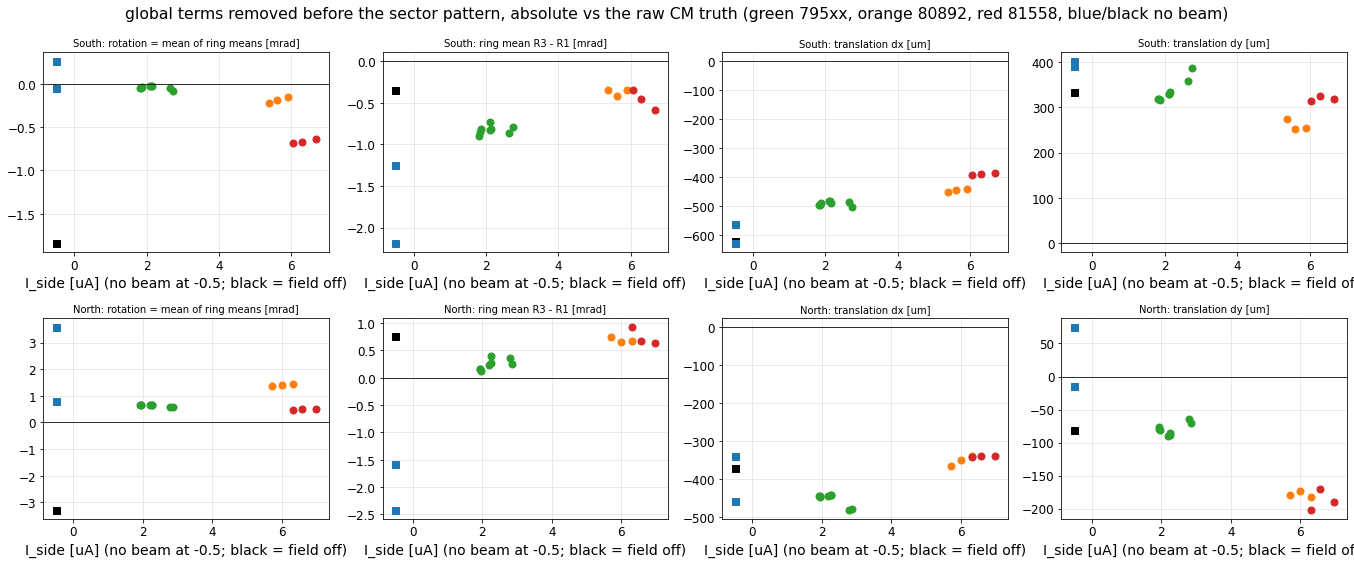

In [24]:
show(cm.fig_global_terms())

## 7. The per-module space-charge pattern
### 7a. The sector patterns of all pairs are the same pattern
Correlation of the rest (after ring means + translation) between pairs. The in-fill pair (79508 − 79516, I falling) anti-correlates
with the cross-fill pairs (79513 − 8xxxx, I rising): the same pattern with the opposite sign of ΔI.

In [25]:
cm.pattern_correlations()

South: correlation of the sector patterns (rest), all rings
                 79508-79516   79513-80892   79513-81558   80892-81558   75073-83319
79508-79516            +1.00         -0.79         -0.83         -0.79         -0.30
79513-80892            -0.79         +1.00         +0.96         +0.66         +0.21
79513-81558            -0.83         +0.96         +1.00         +0.78         +0.25
80892-81558            -0.79         +0.66         +0.78         +1.00         +0.42
75073-83319            -0.30         +0.21         +0.25         +0.42         +1.00
North: correlation of the sector patterns (rest), all rings
                 79508-79516   79513-80892   79513-81558   80892-81558   75073-83319
79508-79516            +1.00         -0.82         -0.84         -0.79         +0.02
79513-80892            -0.82         +1.00         +0.95         +0.74         +0.26
79513-81558            -0.84         +0.95         +1.00         +0.81         +0.25
80892-81558            -0.79  

### 7b. One pattern per µA predicts every pair
**Plotted**: points = sector-to-sector part (rest) of the run change of one pair of blocks, per sector and ring; line = the same
quantity measured on a *different* pair (79513/0 − 81558/0), divided by its ΔI and multiplied by this pair's ΔI. This is **not**
how well the space charge is removed: it is what the maps leave behind, and that it is the same pattern per µA in independent
pairs shows that it is real, current-proportional space charge per module that the maps do not contain.

In [26]:
P = cm.pattern_prediction()

template 79513/0 - 81558/0 per uA x dI of each pair; fitted amplitude k (1 = linear in I), rest rms before -> after, stat error, correlation
   South 79508/0-79516/0 dI +0.88: k +0.96 | rest 0.185 -> 0.103 mrad (stat 0.049) | corr +0.83
   South 79508/1000-79516/2000 dI +0.84: k +1.06 | rest 0.184 -> 0.092 mrad (stat 0.050) | corr +0.87
   South 80892/0-80892/2000 dI +0.53: k +0.63 | rest 0.079 -> 0.053 mrad (stat 0.029) | corr +0.74
   South 81558/0-81558/2000 dI +0.63: k +0.71 | rest 0.105 -> 0.070 mrad (stat 0.031) | corr +0.75
   South 80892/0-81558/0 dI -0.77: k +1.23 | rest 0.218 -> 0.138 mrad (stat 0.050) | corr +0.78
   South 79513/0-80892/0 dI -3.76: k +0.91 | rest 0.632 -> 0.167 mrad (stat 0.099) | corr +0.96
   South 79513/1000-81558/1000 dI -4.18: k +1.00 | rest 0.744 -> 0.097 mrad (stat 0.093) | corr +0.99
   South 79516/0-80892/2000 dI -3.51: k +0.97 | rest 0.629 -> 0.164 mrad (stat 0.115) | corr +0.97
   North 79508/0-79516/0 dI +0.92: k +1.25 | rest 0.213 -> 0.114 mrad 

   North 79513/0-80892/0 dI -4.06: k +1.05 | rest 0.686 -> 0.217 mrad (stat 0.093) | corr +0.95


   North 79513/1000-81558/1000 dI -4.31: k +1.09 | rest 0.737 -> 0.169 mrad (stat 0.106) | corr +0.97
   North 79516/0-80892/2000 dI -3.76: k +1.21 | rest 0.726 -> 0.175 mrad (stat 0.105) | corr +0.97


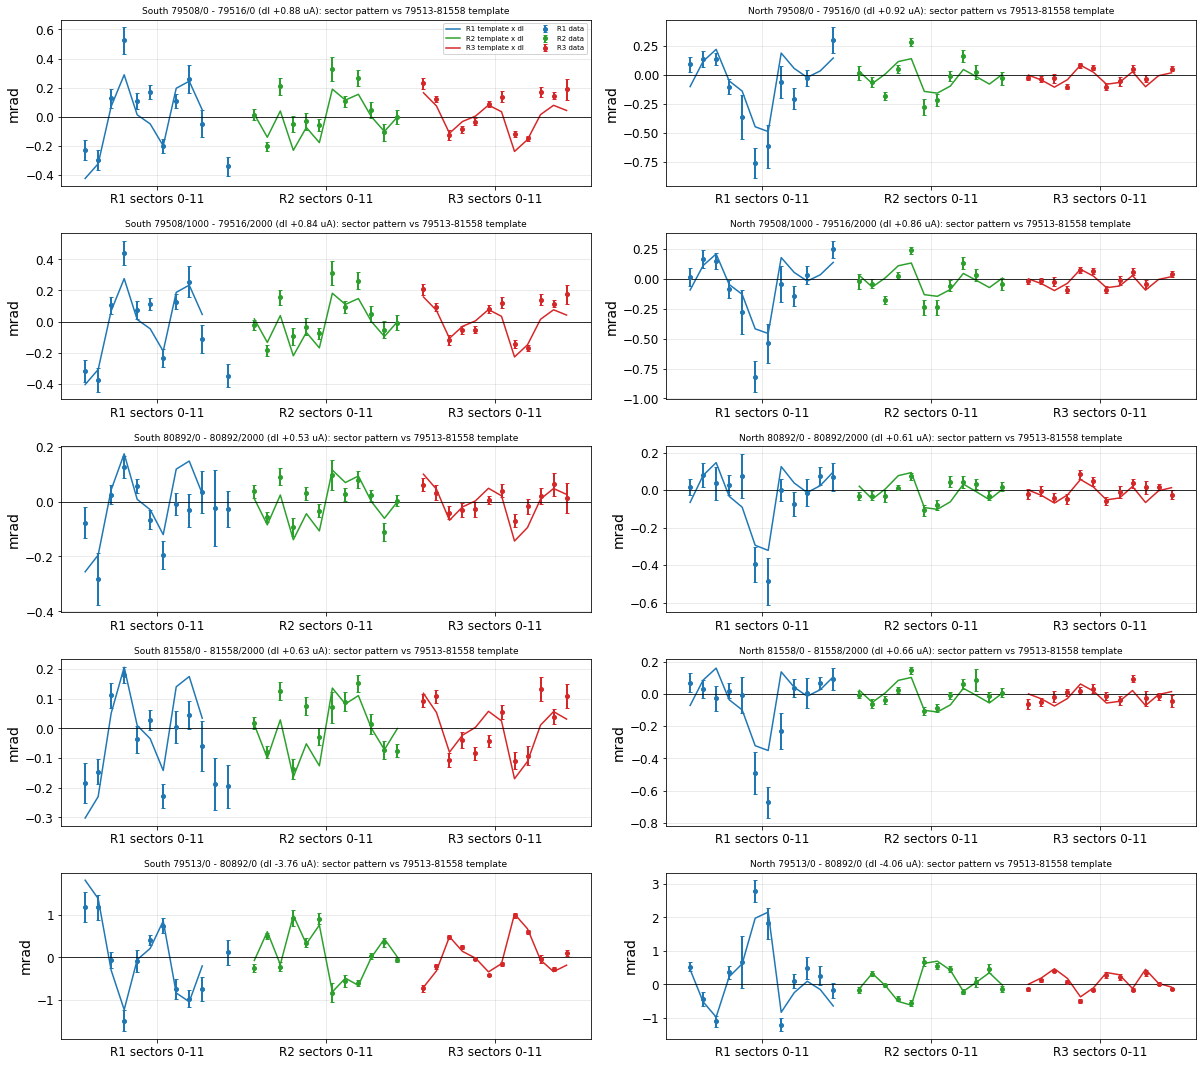

In [27]:
show(cm.fig_pattern_prediction())

Same with the in-fill pair as template (cross-fill k ≈ 0.6–0.7: the pattern grows less than linearly at high current):

In [28]:
P2 = cm.pattern_prediction(template=(('79508', 0), ('79516', 0)), pairs=cm.PRED_PAIRS[1:] + ((('79513', 0), ('81558', 0)),))

template 79508/0 - 79516/0 per uA x dI of each pair; fitted amplitude k (1 = linear in I), rest rms before -> after, stat error, correlation
   South 79508/1000-79516/2000 dI +0.84: k +1.00 | rest 0.184 -> 0.030 mrad (stat 0.050) | corr +0.99
   South 80892/0-80892/2000 dI +0.53: k +0.49 | rest 0.079 -> 0.054 mrad (stat 0.029) | corr +0.74
   South 81558/0-81558/2000 dI +0.63: k +0.66 | rest 0.105 -> 0.052 mrad (stat 0.031) | corr +0.87
   South 80892/0-81558/0 dI -0.77: k +1.01 | rest 0.218 -> 0.134 mrad (stat 0.050) | corr +0.79
   South 79513/0-80892/0 dI -3.76: k +0.60 | rest 0.632 -> 0.391 mrad (stat 0.099) | corr +0.79
   South 79513/1000-81558/1000 dI -4.18: k +0.67 | rest 0.744 -> 0.404 mrad (stat 0.093) | corr +0.84
   South 79516/0-80892/2000 dI -3.51: k +0.65 | rest 0.629 -> 0.376 mrad (stat 0.115) | corr +0.80
   South 79513/0-81558/0 dI -4.53: k +0.66 | rest 0.804 -> 0.450 mrad (stat 0.113) | corr +0.83
   North 79508/1000-79516/2000 dI +0.86: k +1.00 | rest 0.202 -> 0.035

   North 79516/0-80892/2000 dI -3.76: k +0.70 | rest 0.755 -> 0.424 mrad (stat 0.105) | corr +0.83
   North 79513/0-81558/0 dI -4.72: k +0.58 | rest 0.753 -> 0.404 mrad (stat 0.110) | corr +0.84


**Plotted**, step by step: (1) for a pair of blocks A − B, per pad module the median over its stripes of dφ_A − dφ_B
(dφ = corrected cluster φ − truth φ, as in 6b); (2) per side, 3 ring means and a translation (dx, dy) of the pattern fitted and
removed – the rest is how each module changed relative to the others; (3) divided by ΔI = I_A − I_B → mrad/µA. Four independent
pairs: three cross-fill (ΔI ≈ 4 µA, small errors per µA) and one inside the fill (green, ΔI 0.9 µA, larger errors).

**What it is not**: a measure of how well the φ-symmetric dφ(R) (space-charge map shape, keff) is corrected – that part was
reduced to the ring means here (Section 6c and the earlier notebooks). **What it is**: the sector-dependent part of the
current-dependent residual, i.e. per-module space charge the maps do not contain. It is the same in all four pairs, so it is
real and correctable (Section 9, v13 maps). For TPC-standalone tracking a common φ offset (rotation) does not matter and the
translation affects only pointing to the beam, but this sector pattern varies with φ inside the TPC (sector-to-sector
sagitta-like distortions, up to 0.4–0.8 mrad/µA in R1, i.e. 3–5 mrad at 6.7 µA) and does affect tracks.

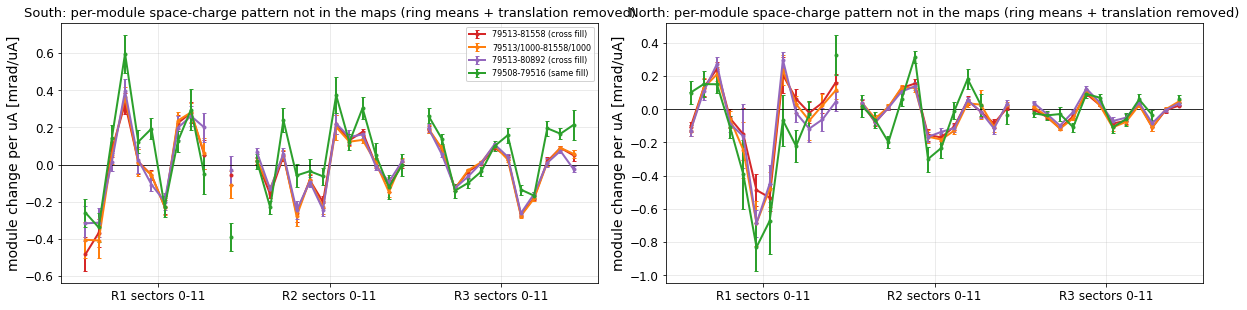

In [29]:
show(cm.fig_pattern_per_uA())

## 8. Static check: one fit of all 14 beam blocks
Module medians of the absolute residual (3-pad COG 2 rows), per side, fitted with
* **nofill**: one static per module A(S, r) + a per-module slope g(S, r) × I;
* **common**: the same + per fill (80892, 81558) ring means and a translation of the pattern (period static of the field cage /
  frames);
* **perfill**: a free static per module and fill + the slope.

χ² uses 0.03 mrad per module median (the stripe jitter averaged over a module); x = I or the shape of the global keff.

In [30]:
F = cm.static_fit(); F2 = cm.static_fit(x='keff')

South nofill   (I): residual rms 0.173 mrad, chi2/ndf 38.88 (err 0.03 mrad, ndf 425)
South common   (I): residual rms 0.087 mrad, chi2/ndf 10.10 (err 0.03 mrad, ndf 415) | 80892: c -0.62 +0.10 -0.02 mrad, dx +39 dy -227 um; 81558: c -1.08 -0.38 -0.54 mrad, dx +93 dy -197 um
South perfill  (I): residual rms 0.062 mrad, chi2/ndf 6.10 (err 0.03 mrad, ndf 353)
North nofill   (I): residual rms 0.329 mrad, chi2/ndf 140.58 (err 0.03 mrad, ndf 426)
North common   (I): residual rms 0.094 mrad, chi2/ndf 11.66 (err 0.03 mrad, ndf 416) | 80892: c +0.28 +1.27 +0.77 mrad, dx +102 dy +7 um; 81558: c -0.68 +0.44 -0.16 mrad, dx +114 dy +11 um
North perfill  (I): residual rms 0.073 mrad, chi2/ndf 8.28 (err 0.03 mrad, ndf 354)
South nofill   (keff): residual rms 0.175 mrad, chi2/ndf 39.85 (err 0.03 mrad, ndf 425)
South common   (keff): residual rms 0.088 mrad, chi2/ndf 10.24 (err 0.03 mrad, ndf 415) | 80892: c -0.58 +0.12 -0.03 mrad, dx +44 dy -235 um; 81558: c -1.02 -0.35 -0.55 mrad, dx +98 dy -203 um
S

North nofill   (keff): residual rms 0.328 mrad, chi2/ndf 139.72 (err 0.03 mrad, ndf 426)
North common   (keff): residual rms 0.094 mrad, chi2/ndf 11.64 (err 0.03 mrad, ndf 416) | 80892: c +0.33 +1.29 +0.75 mrad, dx +106 dy +8 um; 81558: c -0.62 +0.45 -0.17 mrad, dx +119 dy +10 um
North perfill  (keff): residual rms 0.072 mrad, chi2/ndf 8.01 (err 0.03 mrad, ndf 354)


**Static at I = 0 vs no beam**: the sector pattern (ring means + translation removed) of A from the *common* fit, compared with the
no-beam runs (same raw truth, same estimator).

In [31]:
cm.static_vs_nobeam(fit=F)

sector pattern of the static (ring means + translation removed): rms [mrad] and correlation
South: beam fit A(I=0) rest rms 0.494 | 75073: rms 0.477, corr +0.89, rms diff 0.222 | 83319: rms 0.386, corr +0.88, rms diff 0.248 | 78242: rms 0.489, corr +0.34, rms diff 0.565
North: beam fit A(I=0) rest rms 0.754 | 75073: rms 0.739, corr +0.91, rms diff 0.310 | 83319: rms 0.625, corr +0.83, rms diff 0.409 | 78242: rms 0.802, corr +0.72, rms diff 0.580


{0: {'nofill': {'rms': 0.17297283753901163,
   'chi2': 38.875927988417686,
   'ndf': 425,
   'g': array([[-0.46294579,  0.04837806,  0.1735767 ],
          [-0.40716738, -0.11418217,  0.00433517],
          [-0.07938549,  0.02297753, -0.23630909],
          [ 0.12302458, -0.20864738, -0.17020439],
          [-0.2176103 , -0.1716299 , -0.10862569],
          [-0.32668052, -0.27319057, -0.04731935],
          [-0.42745404,  0.09427027, -0.10172592],
          [ 0.00561585,  0.06285597, -0.38521069],
          [ 0.15347847,  0.16206263, -0.28538234],
          [ 0.01357931,  0.02239261, -0.03385935],
          [-0.51747422, -0.03932991,  0.05157667],
          [-0.0704049 ,  0.01508563,  0.04131926]]),
   'A': {0: array([[ 1.24845764, -0.23800116, -0.32066763],
           [ 0.82950637,  0.34936818, -0.0191356 ],
           [ 1.52976622,  0.3145106 ,  0.17275477],
           [ 3.36739948,  0.38742315,  0.98530397],
           [ 2.5925056 ,  1.30914914,  1.18355239],
           [ 2.46906188

**Plotted**: left, the static sector pattern at I = 0 per fill (*perfill* fit, ring means + translation removed) and the no-beam
runs; right, the per-module slope dY/dI (mrad/µA) of the common fit, with and without its ring means + translation.

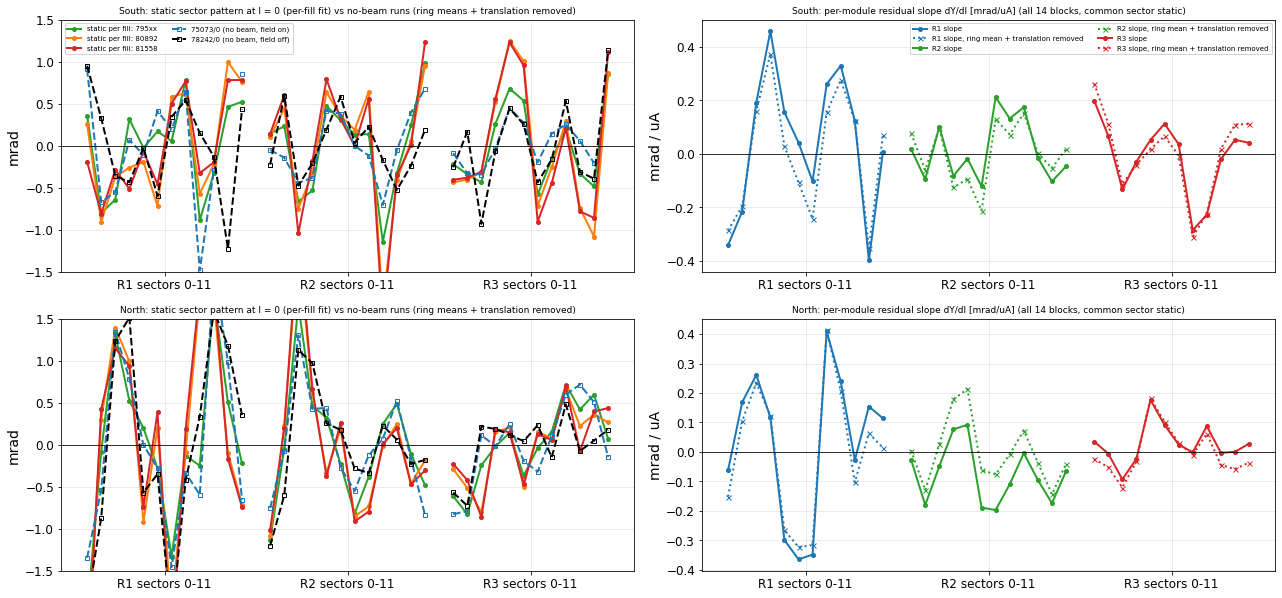

In [32]:
show(cm.fig_static_gain(fit=F))

## 9. Per-module gain from the slope (v12 module basis)
Each pad module m has a field map from its own charge (v12: 72 Rossegger solutions at the module's charge fraction f_m; their
sum is the final map). On 79513/1000 the CM response of each module map is measured per cell (sector × ring × φ half × R half,
144 cells per side) and divided by the block current. The measured residual slope per cell (14-block fit as in Section 8,
cells instead of modules) is fitted with g(c) = −Σ_m δ_m R_m(c) + ring means + translation, δ_m = relative change of module m's
charge (ridge 0.02), **keeping the charge of every ring** (Σ_j f_jk δ_jk = 0, so the global keff and the radial shape calibrated
before stay unchanged). Without that constraint the fit also lowers the total charge by 7–11 % (slope rms 0.10 instead of 0.14 /
0.12 mrad/µA) – a hint that the global keff is slightly high; tested separately with the f13_gainfree map.

**Plotted**: left, δ_m in % per module (hardware sector numbering); right, measured slope per cell (black) and the fit (red).

South: cell slopes rms 0.227 mrad/uA; after nuisance only 0.229, after module weights 0.139 | delta (charge change) rms 0.17, range -0.26..+0.39
North: cell slopes rms 0.211 mrad/uA; after nuisance only 0.209, after module weights 0.121 | delta (charge change) rms 0.12, range -0.32..+0.28


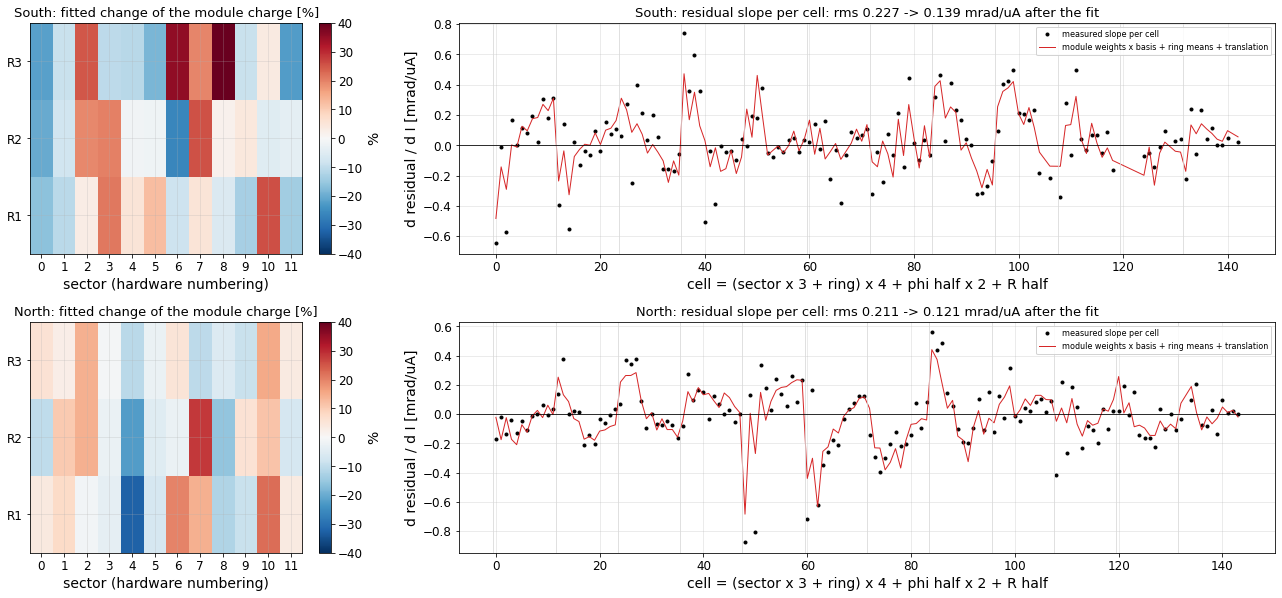

In [33]:
G = cm.gain_fit(lam=0.02)
show(cm.fig_gain(G))

Without the charge constraint (for comparison):

South: cell slopes rms 0.227 mrad/uA; after nuisance only 0.294, after module weights 0.104 | delta (charge change) rms 0.15, range -0.35..+0.19
North: cell slopes rms 0.211 mrad/uA; after nuisance only 0.215, after module weights 0.093 | delta (charge change) rms 0.12, range -0.39..+0.28


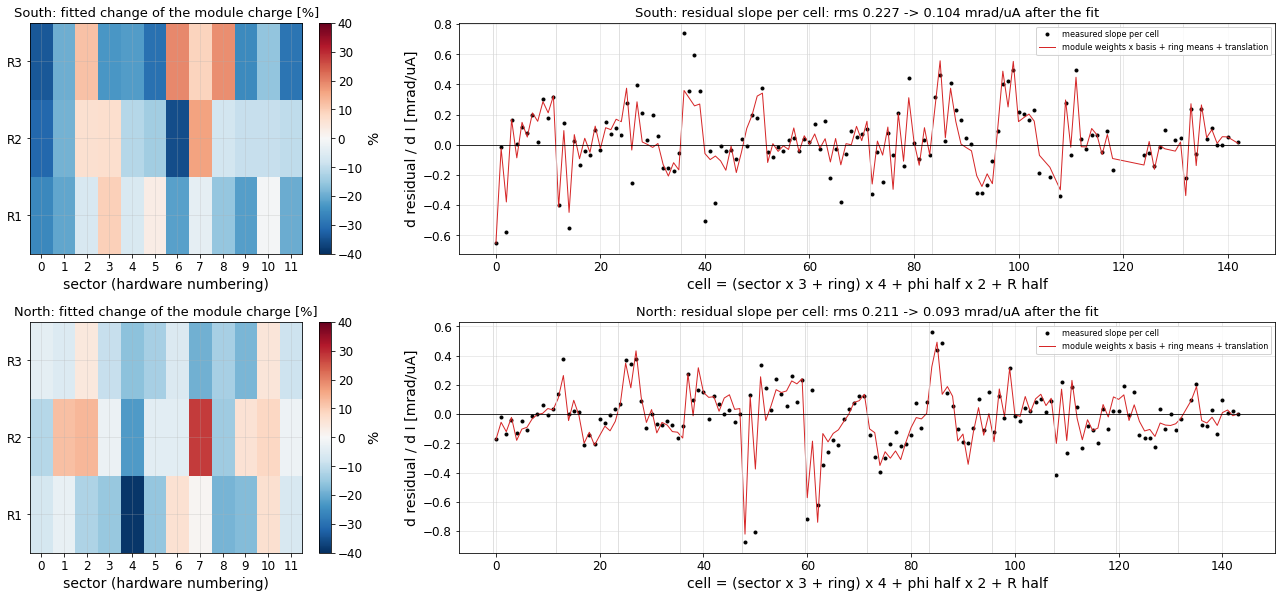

In [34]:
Gf = cm.gain_fit(lam=0.02, conserve=False)
show(cm.fig_gain(Gf))

In [35]:
cm.gain_stability()

South: cell slopes rms 0.227 mrad/uA; after nuisance only 0.229, after module weights 0.139 | delta (charge change) rms 0.17, range -0.26..+0.39
North: cell slopes rms 0.211 mrad/uA; after nuisance only 0.209, after module weights 0.121 | delta (charge change) rms 0.12, range -0.32..+0.28

module weights from data subsets vs all 14 blocks


South: cell slopes rms 0.230 mrad/uA; after nuisance only 0.229, after module weights 0.138 | delta (charge change) rms 0.17, range -0.25..+0.36
North: cell slopes rms 0.215 mrad/uA; after nuisance only 0.210, after module weights 0.118 | delta (charge change) rms 0.13, range -0.33..+0.26
  without 80892            South: corr +1.00, rms diff 0.014 | North: corr +0.99, rms diff 0.014


South: cell slopes rms 0.226 mrad/uA; after nuisance only 0.231, after module weights 0.144 | delta (charge change) rms 0.18, range -0.27..+0.48
North: cell slopes rms 0.218 mrad/uA; after nuisance only 0.214, after module weights 0.135 | delta (charge change) rms 0.12, range -0.33..+0.31
  without 81558            South: corr +0.99, rms diff 0.024 | North: corr +0.99, rms diff 0.021


South: cell slopes rms 0.279 mrad/uA; after nuisance only 0.277, after module weights 0.166 | delta (charge change) rms 0.19, range -0.32..+0.47
North: cell slopes rms 0.349 mrad/uA; after nuisance only 0.343, after module weights 0.249 | delta (charge change) rms 0.22, range -0.76..+0.37
  only 795xx (one fill)    South: corr +0.72, rms diff 0.135 | North: corr +0.73, rms diff 0.157
South: cell slopes rms 0.338 mrad/uA; after nuisance only 0.325, after module weights 0.229 | delta (charge change) rms 0.22, range -0.39..+0.66
North: cell slopes rms 0.380 mrad/uA; after nuisance only 0.381, after module weights 0.306 | delta (charge change) rms 0.23, range -0.37..+0.65
  only 80892 + 81558       South: corr +0.60, rms diff 0.181 | North: corr +0.67, rms diff 0.171


## 10. v13: the same clusters corrected with the CM module weights
Configurations (all 14 beam blocks, the final f9_sper settings – per-period static, keff – with only the maps replaced):
f13_ref = f9_sper (check: identical corrections), f13_gain = module charges × (1 + δ) at fixed charge per ring, f13_gainh = half of
it, f13_gainfree = δ without the charge constraint.

Tabulated per configuration: rms of the residual slope per cell (Section 9), the sector rest per µA of four pairs (Section 7),
the 14-block static fit residual (Section 8), and per block the absolute ring means (global level) and the sector rest rms.

In [36]:
R13 = cm.v13_summary()

per configuration (South | North):
  cell slope rms [mrad/uA] | sector rest per uA: 79513-81558, 79508-79516, 80892-81558, 79513/1000-81558/1000 [mrad/uA] | 14-block static fit residual (common) [mrad]
  f9_sper       0.227 | 0.178 0.211 0.284 0.178 | 0.087   ||   0.211 | 0.154 0.232 0.295 0.171 | 0.094   ||   
  f13_ref       0.227 | 0.178 0.211 0.284 0.178 | 0.087   ||   0.211 | 0.154 0.232 0.295 0.171 | 0.094   ||   
  f13_gainh     0.179 | 0.130 0.172 0.239 0.126 | 0.075   ||   0.160 | 0.100 0.181 0.257 0.108 | 0.087   ||   
  f13_gain      0.156 | 0.088 0.144 0.194 0.084 | 0.075   ||   0.135 | 0.059 0.152 0.224 0.058 | 0.081   ||   
  f13_gainfree  0.231 | 0.075 0.157 0.189 0.081 | 0.080   ||   0.124 | 0.060 0.149 0.240 0.057 | 0.091   ||   

absolute ring means c R1/R2/R3 [mrad] (global level) and sector rest rms [mrad] per block:
  79508/0     S: f9_sper:+0.46 -0.37 -0.33 r0.66  f13_gain:+0.43 -0.37 -0.33 r0.50  f13_gainf:+1.15 -0.74 -0.95 r0.47 N: f9_sper:+0.54 +0.35 +0.80 r0.9

**Plotted**: the sector pattern per µA left in the residual (as Section 7c) with the final maps (top), the CM module weights
(middle) and the unconstrained weights (bottom).

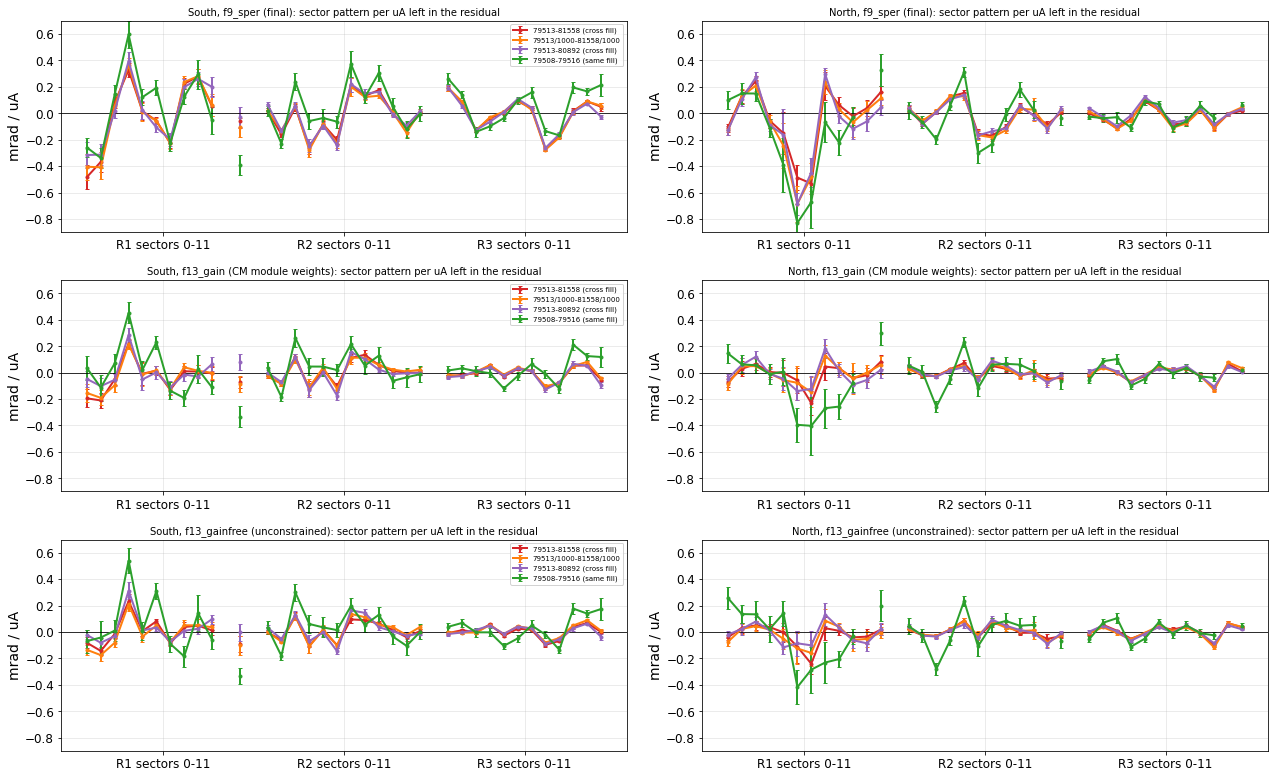

In [37]:
show(cm.fig_v13_patterns())

**Reading**: with f13_gain the current-dependent sector pattern drops by 2–2.6× in the cross-fill pairs (0.18 → 0.09, 0.15 →
0.06 mrad/µA), half of it with f13_gainh (linear), and the absolute sector rest becomes nearly independent of the current
(South 0.47–0.64, North 0.71–0.81 mrad instead of up to 1.2 / 1.4): what is left is the per-module static of Section 8. The global
level (ring means) is unchanged. The unconstrained weights reduce the pattern equally but move the ring means by up to 1.5 mrad –
the lower total charge they ask for is not supported by the global dφ(R): rejected.

## 11. Summary and next steps
* **Cluster position**: module centroid S-curve 150–400 µm; 3-pad COG on the raw pad sums (2 rows) 50–100 µm and half the
  stripe jitter in R3 → proposal for `LaserAggregatedClusterizer`. Stripe-specific errors (~100–250 µm) remain with any
  estimator and after the DNL correction: never interpret single stripes; module averages are fine.
* **Static**: a per-module static of 0.5–0.75 mrad rms exists, the same with beam (extrapolated to I = 0) and without beam. Next:
  take it from the beam fit / no-beam runs as a per-module static table (or model it: module positions / frame charge).
* **Gain**: per-module charges redistributed by ±12–17 % rms at fixed charge per ring (v13 f13_gain): the current-dependent
  sector pattern drops 2–2.6×, the residual slope per cell 0.22 → 0.14–0.16 mrad/µA, global level unchanged. Next: iterate once
  (refit δ on the v13 residuals), and the per-module static table.